In [6]:
import os, glob, sys, importlib
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt
from tqdm import tqdm
import plot_utils
import scipy.stats as st

plt.rcParams["font.size"] = '10'



def interp4small_gaps(data, max_gap = pd.Timedelta("1h")):
    # Максимальная длина пропуска (в времени): 1 час
        
    # Восстанавливаем Series
    filled = data.copy()
    mask = data.isna()

    # Определяем группы пропущенных значений
    gap_groups = (mask != mask.shift()).cumsum()[mask]

    # Для каждой группы пропусков
    for name, group in mask.groupby(gap_groups):
        indices = group.index
        start = indices[0]
        end = indices[-1]

        # Длина пропуска — разница между следующим и предыдущим НЕnan значениями
        prev_time = data.loc[:start].last_valid_index()
        next_time = data.loc[end:].first_valid_index()

        if prev_time is None or next_time is None:
            continue  # не можем оценить длину (в начале или конце)

        gap_duration = next_time - prev_time

        if gap_duration <= max_gap:
            # Интерполируем только в пределах этой группы
            filled.loc[start:end] = data.loc[start:end].interpolate(method='linear', limit_direction='both')
    return filled


### Data availibility plot

In [7]:

data_dir = r"D:\!Work\IFA\!data\Urban_fluxes_NE\processed"

# city_name = 'Moscow'
# ds_name = ''

city_name = 'Tomsk'
ds_name = 'new_py' #ds_name = 'new_rot3'

# city_name = 'Beijing'
# ds_name = ''

time_zones = {'Moscow':3, 'Tomsk':7, 'Beijing':8}

df4sites = {}

file_pattern = data_dir + '/' + city_name + ('_' if ds_name else '') + ds_name + '/L1/*.csv'
display(file_pattern)

for file in glob.glob(file_pattern):
    site = os.path.basename(file).split('.')[0]
    print (file)
    df = pd.read_csv(file, index_col=0, parse_dates=True)
    df.index = df.index + pd.Timedelta(hours=time_zones[city_name])
    #if site == 'ZNS_56m':
    #    df = df.drop(index=[i for i in df.index if i > pd.Timestamp (2022,2,1) and i < pd.Timestamp (2022,6,14)])
    df4sites[site] = df

print (df4sites.keys())

'D:\\!Work\\IFA\\!data\\Urban_fluxes_NE\\processed/Tomsk_new_py/L1/*.csv'

D:\!Work\IFA\!data\Urban_fluxes_NE\processed/Tomsk_new_py/L1\BEK_30m.csv
D:\!Work\IFA\!data\Urban_fluxes_NE\processed/Tomsk_new_py/L1\IMCESmezo_30m.csv
D:\!Work\IFA\!data\Urban_fluxes_NE\processed/Tomsk_new_py/L1\IMCES_30m.csv
D:\!Work\IFA\!data\Urban_fluxes_NE\processed/Tomsk_new_py/L1\IMCES_40m.csv
D:\!Work\IFA\!data\Urban_fluxes_NE\processed/Tomsk_new_py/L1\Oblkom_30m.csv
D:\!Work\IFA\!data\Urban_fluxes_NE\processed/Tomsk_new_py/L1\Voronino_10m.csv
dict_keys(['BEK_30m', 'IMCESmezo_30m', 'IMCES_30m', 'IMCES_40m', 'Oblkom_30m', 'Voronino_10m'])


In [8]:
df = pd.DataFrame()

for site in df4sites.keys():
    df4site = df4sites[site].copy()
    df4site = df4site.rename(columns = {c: site + '_' + c for c in df4site.columns})
    df = df.merge(df4site, how = 'outer', right_index = True, left_index = True)

for col in [c for c in df.columns if 'ERA5' in c]: 
    df[col] = df[col].interpolate(method = 'linear')

display(df.head())

,BEK_30m_Qh,BEK_30m_Qtau,BEK_30m_Ustar,BEK_30m_T_air,BEK_30m_RH_air,BEK_30m_P_air,BEK_30m_Rho_air,BEK_30m_u,BEK_30m_v,BEK_30m_Wind_W,...,Voronino_10m_Wind_U,Voronino_10m_Wind_V,Voronino_10m_Wind_dir,Voronino_10m_Wind_alpha,Voronino_10m_Wind_W_std,Voronino_10m_Cd,Voronino_10m_qc_tot,Voronino_10m_qc_tot_noCd,Voronino_10m_qc_tot_ext,Voronino_10m_qc_tot_noCd_ext
2023-12-31 00:00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2023-12-31 00:20:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2023-12-31 00:40:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2023-12-31 01:00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2023-12-31 01:20:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [9]:
from plotly.subplots import make_subplots
import plotly.graph_objects as go
import plotly.express as px

pd.options.plotting.backend = 'plotly'

colors = px.colors.qualitative.Plotly

fig = make_subplots(rows=2, cols=1, shared_xaxes=True, vertical_spacing=0.04)
for i, c in enumerate([c for c in df.columns if 'Qtau' in c]):
    if 'ERA5' not in c:
        site = c.replace('_Qtau', '')
        data2draw = df[c].where(df[f'{site}_qc_tot'] > 0)
    else:
        data2draw = df[c]
    fig.add_trace(go.Scatter(x=df.index, y=data2draw, name=c), row=1, col=1)

for i, c in enumerate([c for c in df.columns if 'Qh' in c]):
    if 'ERA5' not in c:
        site = c.replace('_Qh', '')
        data2draw = df[c].where(df[f'{site}_qc_tot'] > 0)
    else:
        data2draw = df[c]
    fig.add_trace(go.Scatter(x=df.index, y=data2draw, name=c, line=dict(color = colors[i])), row=2, col=1)
fig.update_yaxes(range=[-300, 600], row=2, col=1)
fig.update_layout(margin=dict(l=0, r=0, t=0, b=0))
fig.show()
#df[[c for c in df.columns if 'Qtau' in c]].plot()

### Filter data and select days with low gaps ratio

['BEK_30m', 'Oblkom_30m']

['IMCES_40m', 'Oblkom_30m']

['BEK_30m', 'IMCES_40m', 'Oblkom_30m']

['BEK_30m', 'Voronino_10m', 'IMCES_40m', 'Oblkom_30m']

['Voronino_10m', 'IMCES_40m', 'Oblkom_30m']

['BEK_30m', 'IMCES_40m', 'IMCESmezo_30m', 'Oblkom_30m']

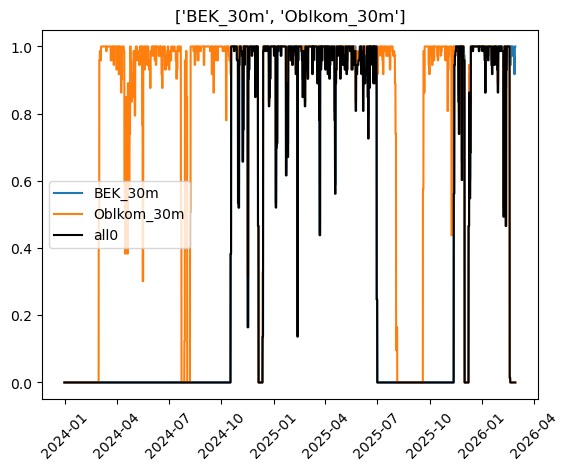

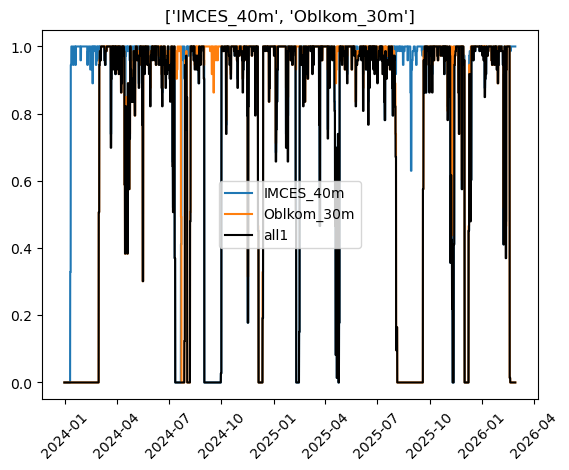

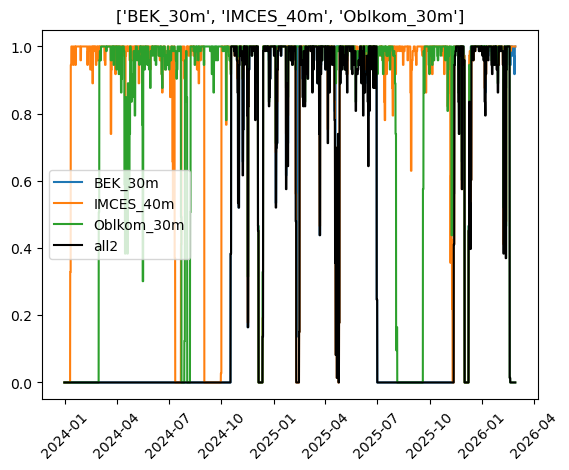

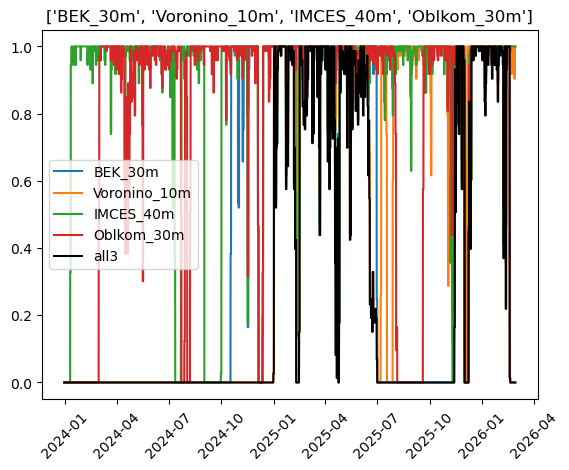

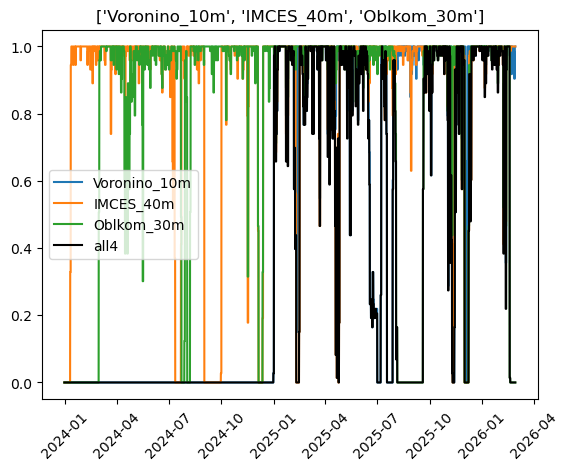

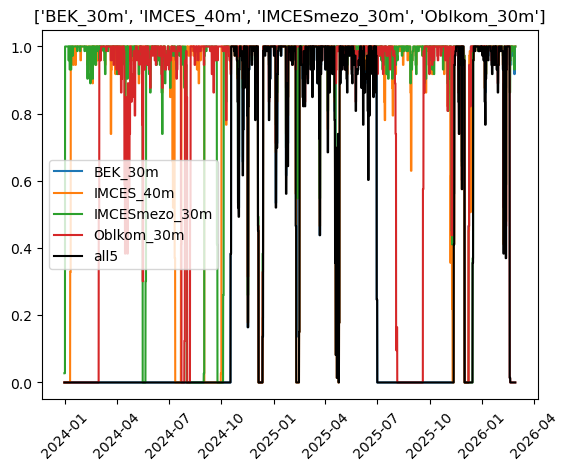

In [10]:
#matplotlib inline
#%matplotlib qt
sites = df4sites.keys()

def is_ok4day (df, unique_dates, is_ok_name):
    df['is_ok4day_' + is_ok_name] = np.zeros((df.shape[0],1))
    for unique_date in unique_dates:
        sel_times = slice (pd.Timestamp(unique_date), pd.Timestamp(unique_date) + pd.Timedelta(days=1))
        n = df[sel_times].shape[0]
        n_ok = np.sum(df[sel_times]['is_ok_' + is_ok_name])
        df.loc[sel_times, 'is_ok4day_' + is_ok_name] = n_ok/n
    return df
unique_dates = np.unique(df.index.date)

if city_name == 'Moscow':
    sites2draw_sets = [['ERA5', 'MSU_11m', 'MSU_19m'], ['ERA5', 'MSU_19m'], ['ERA5', 'MSU_19m', 'ZNS_56m'], ['MSU_19m']]
    vars2draw = ['Wind_vel', 'Qtau', 'Qh', 'Cd']
elif city_name == 'Tomsk':
    #sites2draw_sets = [['Oblkom', 'BEK'], ['Oblkom', 'IMCES40m']]
    sites2draw_sets = [['BEK_30m','Oblkom_30m'], 
                       ['IMCES_40m', 'Oblkom_30m'],
                       ['BEK_30m', 'IMCES_40m', 'Oblkom_30m'],
                       ['BEK_30m', 'Voronino_10m', 'IMCES_40m', 'Oblkom_30m'],
                       ['Voronino_10m', 'IMCES_40m', 'Oblkom_30m'],
                       ['BEK_30m', 'IMCES_40m', 'IMCESmezo_30m', 'Oblkom_30m']] 
    #, ['Oblkom', 'IMCES_40m'], ['Oblkom', 'IMCES_40m', 'IMCES_MEZO_30m']]
    #sites2draw_sets = [['Oblkom', 'BEK', 'ERA5'], ['Oblkom', 'BEK', 'IMCES_40m'], ['Oblkom', 'IMCES_40m'], ['Oblkom', 'IMCES_40m', 'IMCES_MEZO_30m']]
    
    vars2draw = ['T_air', 'Wind_vel', 'Qtau', 'Qh', 'Cd'] #Wind_W
elif city_name == 'Beijing':
    #sites2draw_sets = [['ERA5', 'Beijing_47m', 'Beijing_80m', 'Xianghe_32m', 'Xianghe_80m']] 
    sites2draw_sets = [['Beijing_47m', 'Beijing_80m', 'Xianghe_32m', 'Xianghe_80m'],
                       ['Beijing_47m', 'Beijing_80m', 'Xianghe_32m'],
                       ['Beijing_47m', 'Xianghe_32m'],
                       ['Beijing_80m', 'Xianghe_80m']] 
    
    #sites2draw_sets = [['Beijing_80m', 'Xianghe_80m'], ['Beijing_47m', 'Xianghe_32m'], ['Beijing_47m', 'Beijing_80m', 'Xianghe_32m', 'Xianghe_80m']] 
    vars2draw = ['Wind_vel', 'Qtau', 'Qh', 'Cd']

qc_var = 'qc_tot'

for site in sites:
    if site != 'ERA5':
        df['is_ok_' + site] = np.logical_and.reduce([~np.isnan(df[site + '_' + var]) & df[site + '_' + qc_var] for var in vars2draw])
    else:
        df['is_ok_' + site] = np.ones_like(df[site + '_' + vars2draw[0]])
    
    df = is_ok4day (df, unique_dates, site)

df = is_ok4day (df, unique_dates, site)

for i, sites2draw in enumerate(sites2draw_sets):
    display(sites2draw)
    df['is_ok_all' + str(i)] = np.logical_and.reduce([df['is_ok_' + site] if 'is_ok_' + site in df.columns else np.zeros(df.index.shape) for site in sites2draw])
    df = is_ok4day (df, unique_dates, 'all' + str(i))

    plt.figure()
    for site in sites2draw:
        if  'is_ok4day_' + site in df.columns:
            plt.plot (df['is_ok4day_' + site], label = site)        
    plt.plot(df['is_ok4day_all' + str(i)], color='black', label = 'all' + str(i))
    plt.legend()
    _ = plt.xticks(rotation = 45)
    plt.title(str(sites2draw))

In [11]:


from calendar import monthrange
import matplotlib.ticker
#periods = [slice(pd.Timestamp(2022,m,1),pd.Timestamp(2022,m,1) + pd.Timedelta (days = monthrange(2022,m)[1]) - pd.Timedelta (hours=1)) for m in [11,12]] + \
#          [slice(pd.Timestamp(2023,m,1),pd.Timestamp(2023,m,1) + pd.Timedelta (days = monthrange(2023,m)[1]) - pd.Timedelta (hours=1)) for m in [5,6,7]]


#periods = [slice(pd.Timestamp(2023,m,1),pd.Timestamp(2023,m,1) + pd.Timedelta (days = monthrange(2023,m)[1]) - pd.Timedelta (hours=1)) for m in [7, 8,11,12]] + \
#          [slice(pd.Timestamp(2024,m,1),pd.Timestamp(2024,m,1) + pd.Timedelta (days = monthrange(2024,m)[1]) - pd.Timedelta (hours=1)) for m in [1,6]] #+ [slice(pd.Timestamp(2023,m,1),pd.Timestamp(2023,m,1) + pd.Timedelta (days = monthrange(2023,m)[1]) - pd.Timedelta (hours=1)) for m in [5,6,7]]

# periods = [slice(pd.Timestamp(2022,m,1),pd.Timestamp(2022,m,1) + pd.Timedelta (days = monthrange(2022,m)[1]) - pd.Timedelta (hours=1)) for m in range(12,13)] + \
#           [slice(pd.Timestamp(2023,m,1),pd.Timestamp(2023,m,1) + pd.Timedelta (days = monthrange(2023,m)[1]) - pd.Timedelta (hours=1)) for m in range(5,13)]  + \
#           [slice(pd.Timestamp(2024,m,1),pd.Timestamp(2024,m,1) + pd.Timedelta (days = monthrange(2024,m)[1]) - pd.Timedelta (hours=1)) for m in range(1,9)] #+ \
#           #[slice(pd.Timestamp(2024,8,1),pd.Timestamp(2024,8,6), slice(pd.Timestamp(2024,8,8),pd.Timestamp(2024,9,1)))]





if city_name == 'Moscow':
    periods = [slice(pd.Timestamp(2020,11,1),pd.Timestamp(2021,1,1)),
               slice(pd.Timestamp(2021,1,1),pd.Timestamp(2021,3,1)), 
               slice(pd.Timestamp(2021,6,1),pd.Timestamp(2021,9,1)), 
               slice(pd.Timestamp(2022,1,1),pd.Timestamp(2022,3,1)),
               slice(pd.Timestamp(2022,6,1),pd.Timestamp(2022,9,1))]
elif city_name == 'Beijing':
    periods = [slice(pd.Timestamp(2023,12,1),pd.Timestamp(2024,1,1)), 
               slice(pd.Timestamp(2024,1,1), pd.Timestamp(2024,2,1)),
               slice(pd.Timestamp(2023,12,1),pd.Timestamp(2024,2,1)), 
               slice(pd.Timestamp(2024,6,1), pd.Timestamp(2024,7,1))
               ]
elif city_name == 'Tomsk':
    # periods = [slice(pd.Timestamp(2025,6,1),  pd.Timestamp(2025,7,1)),
    #            slice(pd.Timestamp(2025,6,1),  pd.Timestamp(2025,9,1)), 
    #            slice(pd.Timestamp(2025,11,1), pd.Timestamp(2026,3,1))]
    periods = [slice(pd.Timestamp(2025,m,1),  pd.Timestamp(2025+(m==12),m+1 if m+1 <= 12 else np.mod(m+1,12),1)) 
              for m in range (1, 13)] + \
             [slice(pd.Timestamp(2026,m,1),  pd.Timestamp(2026+(m==12),m+1 if m+1 <= 12 else np.mod(m+1,12),1)) 
              for m in range (1, 13)]
    
    # periods = [
    #            slice(pd.Timestamp(2022,12,1), pd.Timestamp(2023,1,1)),
    #            slice(pd.Timestamp(2023,6,1),  pd.Timestamp(2023,7,1)),
    #            slice(pd.Timestamp(2024,8,1),  pd.Timestamp(2024,9,1)),
    #            slice(pd.Timestamp(2024,12,1), pd.Timestamp(2025,1,1)), 
    #            slice(pd.Timestamp(2025,1,1),  pd.Timestamp(2025,2,1)), 
    #            slice(pd.Timestamp(2025,2,1),  pd.Timestamp(2025,3,1)), 
    #            slice(pd.Timestamp(2025,5,1),  pd.Timestamp(2025,6,1)), 
    #            slice(pd.Timestamp(2025,6,1),  pd.Timestamp(2025,7,1))]

    
    



In [12]:
%matplotlib inline
importlib.reload(plot_utils)
plt.rcParams["font.size"] = 12


lang = 'ru'

vars2draw_labels = plot_utils.config_vars(lang)
site_names2draw, site_colors, site_styles = plot_utils.config_city(city_name, lang)


y_lims = {'Wind_vel': [0,5], 
           'w':  [-0.6,0.6],
           'Qh': [-50, 200],
           'Qtau': [0,1],
           'Cd': [0, 0.1]}


if city_name == 'Moscow':
    #vars2draw = ['T_air', 'Wind_vel', 'Qtau', 'Qh', 'Cd']
    vars2draw = ['Qtau', 'Qh', 'Cd']
elif city_name == 'Beijing':
    #vars2draw = ['Wind_vel', 'Qtau', 'Qh', 'Qle', 'Cd']
    vars2draw = ['Qtau', 'Qh', 'Qle', 'Cd']
    y_lims['Qh'] = [-50, 260]
    y_lims['Qle'] = [-50, 260]
    y_lims['Cd'] = [0, 0.2]

elif city_name == 'Tomsk':

    #vars2draw = ['Wind_vel', 'Qtau', 'Qh', 'Qle', 'Cd']
    vars2draw = ['Qtau', 'Qh', 'Cd']
    
    #y_lims['Cd'] = [0, 0.05] 
    #y_lims['Qtau'] = [0,0.8]
    #y_lims['Qh'] = [-50,175]
    
    


save_dir = 'pics_new%s_%s'%(city_name, lang) + '_4Kislovodsk' + '/'

if not os.path.isdir(save_dir):
    os.mkdir (save_dir)

valid_data_frac = 0.9

for period in periods:

    df_sel = df[period]

    is_ok_count = np.zeros(len(sites2draw_sets))
    is_ok4sets = []
    for i_set, sites2draw_set in enumerate(sites2draw_sets):
        is_ok = df_sel['is_ok4day_all' + str(i_set)] > valid_data_frac
        is_ok_count[i_set] = np.sum(is_ok)
        is_ok4sets.append(is_ok)


    for i_set, sites2draw in enumerate(sites2draw_sets):
        if is_ok_count[i_set] == 0:
            continue
    
        is_ok = is_ok4sets[i_set]

        ok_idx  = np.where(is_ok)[0]
        bad_idx = np.where(~is_ok)[0]

        df_sel2 = df_sel.iloc[ok_idx, :]

        n_days = len(np.unique(df_sel2.index.date))

        #fig_name = '%s - %s, sites = %s'%(str(period.start.strftime('%Y.%m.%d'), str(period.stop.strftime('%Y.%m.%d'), str(sites2draw))))
        fig_name = f"{period.start.strftime('%Y%m%d')} - {period.stop.strftime('%Y%m%d')}, sites={str(sites2draw)}, ds={ds_name}, lim={valid_data_frac}"
                                                        
        
        
        for show_raw_data in [False,True]:
            fig, ax = plt.subplots(len(vars2draw), 1,  figsize = (10, 2.5* len(vars2draw)), sharex=True) 
            for i, var in enumerate(vars2draw):
                for site in sites2draw:
                    #df_sel[site + '_' + var].plot(ax = ax[i])
                    data_raw = df_sel[site + '_' + var]
                    data_filtered = data_raw.copy()

                    if site != 'ERA5':
                        data_filtered [~df_sel[site + '_' + qc_var].astype(bool)] = np.nan
                    if site in site_colors.keys():
                        p = ax[i].plot (df_sel.index, data_filtered, label = site, color = site_colors[site])
                    else:
                        p = ax[i].plot (df_sel.index, data_filtered, label = site) #, color = site_colors[site])
                    if show_raw_data:
                        c = p[0].get_color()
                        p = ax[i].plot (df_sel.index, data_raw, color = c, alpha = 0.5)
                        #ax[i].plot(df_sel.index[~df_sel[site + '_filter_passed']], data_raw [site + '_filter_passed'], 'ok')
                    
                ax[i].set_ylabel(vars2draw_labels[var])
                y_lim = list(ax[i].get_ylim())
                
                ok_indicator = np.ones_like(df_sel['is_ok4day_all' + str(i_set)])
                ok_indicator[bad_idx] = np.nan
        
                ax[i].fill_between (df_sel.index, ok_indicator*y_lim[0], ok_indicator*y_lim[1], alpha = 0.25, color = 'green') 
                ax[i].set_ylim(y_lim)
                ax[i].set_xlim((period.start, period.stop))

            plt.suptitle('%s - %s'%(str(period.start.strftime('%Y.%m.%d')), str(period.stop.strftime('%Y.%m.%d'))))
            plt.legend()
            #plt.savefig (save_dir + 'ts' + fig_name + '_raw=%d'%show_raw_data + corr_name + '_qc.png', dpi=300)
            plt.close()

        fig, ax = plt.subplots(1, len(vars2draw), figsize = (4 * len(vars2draw), 4.5))
        plt.subplots_adjust (left = 0.06, wspace = 0.4, right = 0.99, bottom = 0.25)
        
        df4fig = pd.DataFrame()
        for i, var in enumerate(vars2draw):
            daily_means = {}
            for site in sites2draw:
                data_raw = df_sel2[site + '_' + var]
                data_filtered = data_raw.copy()
                if site!= 'ERA5':
                    data_filtered [~df_sel[site + '_' + qc_var].astype(bool)] = np.nan

                #data_filtered = interp4small_gaps(data_filtered)
                for it in range(1,len(data_filtered)-1):
                    if np.isnan(data_filtered.iloc[it]) and ~np.isnan(data_filtered.iloc[it-1]) and ~np.isnan(data_filtered.iloc[it+1]):
                        data_filtered.iloc[it] = 0.5 * (data_filtered.iloc[it-1] + data_filtered.iloc[it+1])
                

                #data_filtered [~df_sel[site + '_' + qc_var].astype(bool)] = np.nan

                hour_means  = data_filtered.groupby([df_sel2.index.hour]).mean()
                hour_stds   = data_filtered.groupby([df_sel2.index.hour]).std()
                hour_counts = data_filtered.groupby([df_sel2.index.hour]).count()

                se = hour_stds / np.sqrt(hour_counts) 
                t_crit = st.t.ppf(0.95, df=hour_counts-1)
                margin = t_crit * se

                ci_lower = hour_means - margin
                ci_upper = hour_means + margin

                
                df4fig[var + '_' + site] = hour_means
                if site in site_colors.keys():
                    ax[i].fill_between(hour_means.index, ci_lower, ci_upper, color = site_colors[site], alpha = 0.25, edgecolor='None')
                    ax[i].plot(hour_means.index, hour_means, label=site_names2draw[site], color = site_colors[site], linestyle = site_styles[site] if site in site_styles.keys() else '-', linewidth = 2) 
                else:
                    ax[i].plot(hour_means.index, hour_means, label=site_names2draw[site], linestyle = site_styles[site] if site in site_styles.keys() else '-', linewidth = 2) 
                
                if var == 'w':
                    ax[i].plot(hour_means.index, hour_stds, '--', label=site_names2draw[site], color = site_colors[site]) 

                daily_means[site] = hour_means.mean()
                
            #if i == 0:
            #ax[i].set_title(var)
            ax[i].set_ylabel(vars2draw_labels[var], labelpad = 2, fontsize='medium', fontweight='bold')
            ax[i].set_xticks(np.arange(0,24+1,6)) 
            ax[i].set_xlabel('Время суток, ч' if lang == 'ru' else 'Daytime, h', fontsize='large', fontweight='bold')
            ax[i].set_xlim((0,24))

            y_lim = list(ax[i].get_ylim())
            x_lim = list(ax[i].get_ylim())
            
            if var in ['Cd', 'Qtau', 'Wind_vel']:
                y_lim[0] = 0

            if var in y_lims.keys():
                y_lim = y_lims[var]    

            
            ax[i].set_ylim(y_lim)

            
            #if var in ['Qh', 'Qtau', 'Qle', 'Cd', 'Wind_vel']:
            fmt = '%.1f' if var in ['Qh', 'Wind_vel', 'T_air'] else '%.2f'
            for i_site, site in enumerate (daily_means.keys()):
                ax[i].annotate (fmt%daily_means[site], (0.95,1-0.08*(1+i_site)), xycoords='axes fraction', ha='right', color = site_colors[site], weight='bold', backgroundcolor=[1,1,1,0.5])
        
            if var == 'T_air':
                ax[i].yaxis.set_major_locator(matplotlib.ticker.MultipleLocator(1))

            ax[i].grid(zorder=0)
            ax[i].axhline(y=0, zorder=0, color = 'black', linewidth = 0.75)

        handles, labels = ax[0].get_legend_handles_labels()
        plt.figlegend(handles, labels, loc="lower center", ncol=len (sites2draw), fontsize='large')
        
        if lang == 'ru':
            plt.suptitle('%s - %s, осреднение за %d дней'%(str(period.start.strftime('%Y.%m.%d')), str(period.stop.strftime('%Y.%m.%d')), n_days), fontsize='large')
        else:
            plt.suptitle('%s - %s, averaging over %d days'%(str(period.start.strftime('%Y.%m.%d')), str(period.stop.strftime('%Y.%m.%d')), n_days), fontsize='large')
        
        plt.savefig (save_dir + 'diurnal_' + fig_name + '.png', dpi=300)
        
        #df4fig.to_csv (save_dir + 'mean_diurnal_turn_' + fig_name + corr_name + '.csv', sep=';')
        plt.close()
        #break


sys.exit()


SystemExit: 

c:\Users\mvar9\anaconda3\envs\ML\Lib\site-packages\IPython\core\interactiveshell.py:3587: UserWarning:

To exit: use 'exit', 'quit', or Ctrl-D.



In [ ]:
pd.options.plotting.backend = "plotly"
df2draw = df[[col for col in df.columns if 'Qh' in col and '30m' not in col]]


for col in df2draw.columns:
    qc_col = df[col.replace('Qh', 'qc')]
    df2draw.loc[qc_col == 0, col] = np.nan #df2draw[col].where(qc_col)

df2draw_renamed = df2draw.rename(columns={col: site_names2draw[col.replace('_Qh', '')] for col in df2draw.columns})

fig = df2draw_renamed['2022.01.01':].plot(color_discrete_sequence=[site_colors[col.replace('_Qh', '')] for col in df2draw.columns])
fig.update_layout(yaxis_title='Sensible heat flux H, W·m-2', xaxis_title = '')
fig.show()




KeyError: 'ERA5_qc'

In [ ]:
from scipy import stats

plt.rcParams['figure.dpi'] = 300
plt.rcParams['savefig.dpi'] = 300

#idx = np.where((df.index > pd.Timestamp (2024, 8, 1)) & np.isin (df.index.month, [11,12,1,2,3]))[0] # & np.isin (df.index.hour, [23,0,1,2,3]))[0]

pairs = [('Oblkom', 'BEK'), ('Oblkom', 'IMCES40m'), ('IMCES40m', 'BEK')]

df_1h = df.resample('1D').mean()
df2draw_1h = df2draw.resample('1D').mean()

idx = np.where((df_1h.index > pd.Timestamp (2022, 8, 1)) & np.isin (df_1h.index.month, [11,12,1,2]))[0] # & np.isin (df.index.hour, [23,0,1,2,3]))[0]

fig, axs = plt.subplots (1, len(pairs), figsize=(12, 4))
plt.subplots_adjust (wspace=0.4)

for pair in pairs:
    plt.sca (axs[pairs.index(pair)])
    urb_site = pair[0]
    rur_site = pair[1]

    x = df_1h[f'{urb_site}_T_air'][idx]
    #x = df_1h[f'{urb_site}_Wind_vel'][idx]

    
    y = df2draw_1h[f'{urb_site}_Qh'][idx] - df2draw_1h[f'{rur_site}_Qh'][idx]

    # idx_sort = np.argsort(x)
    # x = x[idx_sort]
    # y = y[idx_sort]

    idx_xy = np.where (~np.isnan(x) & ~np.isnan(y))[0]

    slope, intercept, r_value, p_value, std_err = stats.linregress(x[idx_xy], y[idx_xy])

    #plt.hexbin (x, y, mincnt=1, gridsize=40)
    plt.plot(x[idx_xy], y[idx_xy], 'ok')

    line = slope * x[idx_xy] + intercept
    plt.plot(x[idx_xy], line, 'r--', label=f'Trend: R²={r_value**2:.3f}')
             
    plt.xlabel (r'Air temperature [°C]')
    plt.ylabel (r'$\Delta$H [W/m$^2$]')
    plt.title (f'{urb_site} - {rur_site}')
    plt.xlim([-30,10])
    plt.ylim([-100,100])
    plt.legend()



NameError: name 'df2draw' is not defined

C:\Users\mvar9\AppData\Local\Temp\ipykernel_27020\1841009529.py:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_sel['delta_Qh'] = df_sel['Oblkom_Qh'] - df_sel['BEK_Qh']
C:\Users\mvar9\AppData\Local\Temp\ipykernel_27020\1841009529.py:7: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  plt.plot (df_sel['Oblkom_Wind_vel'].resample('1H').mean(), df_sel['delta_Qh'].resample('1H').mean(), 'o')


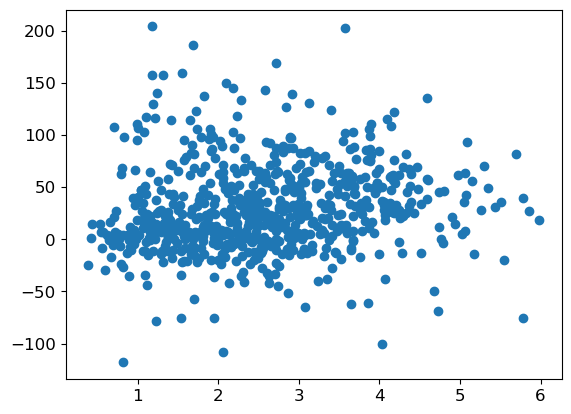

In [ ]:
#df_sel = df['2022-11-01':'2023-02-02']
#df_sel = df['2024-10-01':'2024-11-02']

df_sel['delta_Qh'] = df_sel['Oblkom_Qh'] - df_sel['BEK_Qh']
df_sel.loc[(~df_sel['Oblkom_filter_passed'] | ~df_sel['BEK_filter_passed']), 'delta_Qh'] = np.nan

plt.plot (df_sel['Oblkom_Wind_vel'].resample('1H').mean(), df_sel['delta_Qh'].resample('1H').mean(), 'o')